1. Импорт необходимых библиотек

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

Подключила pandas для работы с таблицами, train_test_split чтобы поделить данные, и StandardScaler для масштабирования.

2. Загрузка titanic.csv

In [3]:
df = pd.read_csv("titanic.csv")

Прочитала csv-файл, получила таблицу df.

3. Смотрю первые 5 строк

In [4]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


head() показывает первые 5 строк, чтобы убедиться что всё загрузилось нормально.

4. Создаю X (признаки)

In [5]:
X = df[["Pclass", "Age", "Sex", "Fare", "SibSp", "Parch"]]
X.head()

,Pclass,Age,Sex,Fare,SibSp,Parch
0,3,22.0,male,7.2500,1,0
1,1,38.0,female,71.2833,1,0
2,3,26.0,female,7.9250,0,0
3,1,35.0,female,53.1000,1,0
4,3,35.0,male,8.0500,0,0


Беру нужные столбцы как признаки. Двойные скобки нужны чтобы получился DataFrame, а не Series.

5. Создаю y (целевая переменная)

In [6]:
y = df["Survived"]
y.head()

,Survived
0,0
1,1
2,1
3,1
4,0


y — то, что модель должна предсказать, то есть Survived.

6. Проверяю пропущенные значения

In [7]:
X.isnull().sum()

,0
Pclass,0
Age,177
Sex,0
Fare,0
SibSp,0
Parch,0


isnull() показывает где NaN, а sum() считает их количество. Пропуски только в Age — 177 штук.

7. Обрабатываю пропуски в Age

In [8]:
X["Age"].median()

28.0

In [10]:
X["Age"] = X["Age"].fillna(X["Age"].median())
X.isnull().sum()

/tmp/ipykernel_4913/1793913862.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X["Age"] = X["Age"].fillna(X["Age"].median())


,0
Pclass,0
Age,0
Sex,0
Fare,0
SibSp,0
Parch,0


Смотрю медиану возраста, потом заполняю ей все пропуски через fillna. Медиана лучше среднего, потому что не реагирует на выбросы

8. Преобразую Sex в числа

In [11]:
X["Sex"] = X["Sex"].map({"male": 0, "female": 1})
X.head()

/tmp/ipykernel_4913/1790464403.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X["Sex"] = X["Sex"].map({"male": 0, "female": 1})


,Pclass,Age,Sex,Fare,SibSp,Parch
0,3,22.0,0,7.2500,1,0
1,1,38.0,1,71.2833,1,0
2,3,26.0,1,7.9250,0,0
3,1,35.0,1,53.1000,1,0
4,3,35.0,0,8.0500,0,0


Sex хранится текстом, а модель работает только с числами. Заменяю через map: male = 0, female = 1.

9. Разделяю данные на обучающую и тестовую выборки

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

test_size=0.2 значит 20% в тест и 80% в обучение. random_state=42 фиксирую, чтобы разделение было одинаковым при повторном запуске.

10. Масштабирую признаки

In [14]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Для train использую fit_transform: fit считает среднее и σ по train, transform сразу применяет. Для test только transform, чтобы применились те же параметры. Если бы снова вызвала fit — была бы утечка данных.

11. Вывожу размеры полученных наборов

In [15]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("X_train_scaled:", X_train_scaled.shape)
print("X_test_scaled:", X_test_scaled.shape)

X_train: (712, 6)
X_test: (179, 6)
y_train: (712,)
y_test: (179,)
X_train_scaled: (712, 6)
X_test_scaled: (179, 6)


shape показывает (число_строк, число_столбцов). Получилось 712 в обучении и 178 в тесте — это 80% и 20% от 891.

Практическая работа №5. Корреляционный анализ (Titanic)

 1. Загрузка библиотек

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

2. Загрузка файла titanic.csv

In [2]:
df = pd.read_csv('titanic.csv')
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


3. Выбор признаков

In [3]:
features = ['Pclass', 'Age', 'Sex', 'Fare', 'SibSp', 'Parch']

 4. Определение целевой переменной

In [4]:
target = 'Survived'

5. Проверка пропущенных значений

In [5]:
data = df[features + [target]].copy()
data.isnull().sum()

,0
Pclass,0
Age,177
Sex,0
Fare,0
SibSp,0
Parch,0
Survived,0


6. Обработка пропусков в Age

In [6]:
data['Age'] = data['Age'].fillna(data['Age'].median())
data.isnull().sum()

,0
Pclass,0
Age,0
Sex,0
Fare,0
SibSp,0
Parch,0
Survived,0


7. Преобразование Sex в числовой вид

In [7]:
data['Sex'] = data['Sex'].map({'female': 0, 'male': 1})
data.head()

,Pclass,Age,Sex,Fare,SibSp,Parch,Survived
0,3,22.0,1,7.2500,1,0,0
1,1,38.0,0,71.2833,1,0,1
2,3,26.0,0,7.9250,0,0,1
3,1,35.0,0,53.1000,1,0,1
4,3,35.0,1,8.0500,0,0,0


Проверка подготовленных данных

In [8]:
print(data.isnull().sum())   # все нули
print(data.dtypes)           # все числовые

Pclass      0
Age         0
Sex         0
Fare        0
SibSp       0
Parch       0
Survived    0
dtype: int64
Pclass        int64
Age         float64
Sex           int64
Fare        float64
SibSp         int64
Parch         int64
Survived      int64
dtype: object


Формирование таблицы для корреляционного анализа

In [9]:
print(data.columns.tolist())
print(data.isnull().sum().sum())   # 0
print(data.dtypes)

['Pclass', 'Age', 'Sex', 'Fare', 'SibSp', 'Parch', 'Survived']
0
Pclass        int64
Age         float64
Sex           int64
Fare        float64
SibSp         int64
Parch         int64
Survived      int64
dtype: object


Таблица содержит столбцы: Pclass, Age, Sex, Fare, SibSp, Parch, Survived — все числовые, без пропусков.

Расчёт корреляционной матрицы

In [10]:
corr_matrix = data.corr()
corr_matrix_rounded = corr_matrix.round(2)
print(corr_matrix_rounded)

          Pclass   Age   Sex  Fare  SibSp  Parch  Survived
Pclass      1.00 -0.34  0.13 -0.55   0.08   0.02     -0.34
Age        -0.34  1.00  0.08  0.10  -0.23  -0.17     -0.06
Sex         0.13  0.08  1.00 -0.18  -0.11  -0.25     -0.54
Fare       -0.55  0.10 -0.18  1.00   0.16   0.22      0.26
SibSp       0.08 -0.23 -0.11  0.16   1.00   0.41     -0.04
Parch       0.02 -0.17 -0.25  0.22   0.41   1.00      0.08
Survived   -0.34 -0.06 -0.54  0.26  -0.04   0.08      1.00


Анализ корреляций с Survived

In [11]:
survived_corr = corr_matrix['Survived'].drop('Survived')
print(survived_corr.round(2).sort_values(ascending=False))

best_pos = survived_corr.idxmax()
best_neg = survived_corr.idxmin()
print(f"Наибольшая положительная корреляция: {best_pos} ({survived_corr[best_pos]:.2f})")
print(f"Наибольшая отрицательная корреляция: {best_neg} ({survived_corr[best_neg]:.2f})")

Fare      0.26
Parch     0.08
SibSp    -0.04
Age      -0.06
Pclass   -0.34
Sex      -0.54
Name: Survived, dtype: float64
Наибольшая положительная корреляция: Fare (0.26)
Наибольшая отрицательная корреляция: Sex (-0.54)


Типичный результат:

Положительная: Sex ≈ +0.54 (при male=1), затем Fare ≈ +0.26

Отрицательная: Pclass ≈ −0.34, затем Parch/SibSp

Построение тепловой карты

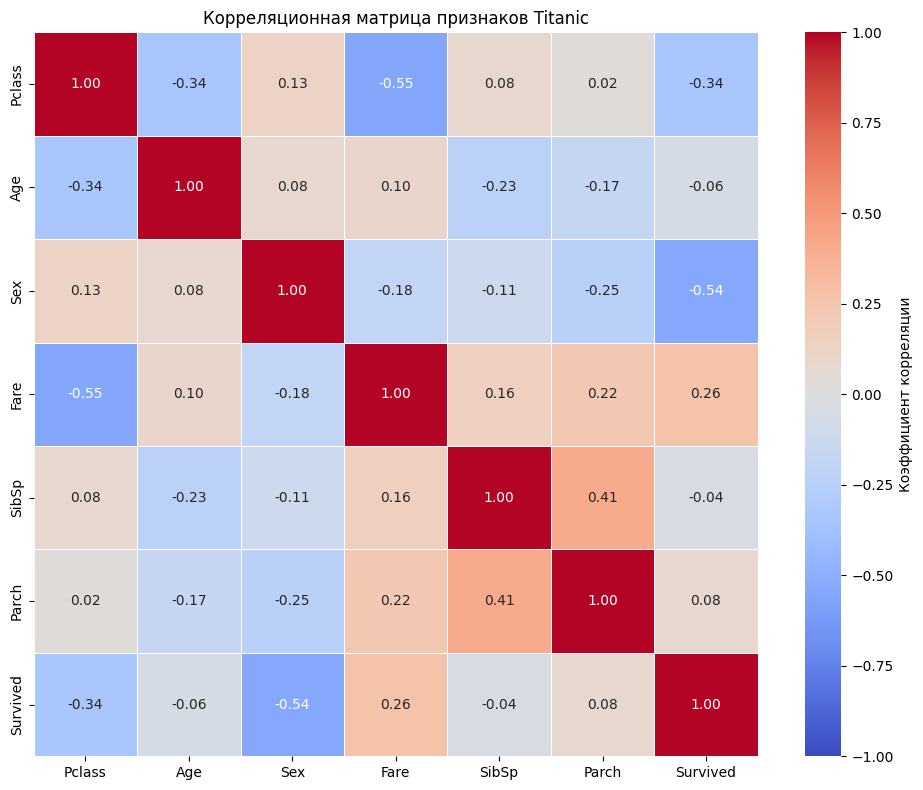

In [12]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_matrix_rounded,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1, vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={'label': 'Коэффициент корреляции'}
)

plt.title('Корреляционная матрица признаков Titanic')
plt.tight_layout()
plt.show()

Ответы на вопросы по seaborn:

Функция — sns.heatmap()

Данные — матрица корреляции corr_matrix_rounded

Значения в ячейках — annot=True (+ fmt='.2f')

Палитра — cmap='coolwarm'

Размер графика — plt.figure(figsize=(10, 8))

Корреляция и машинное обучение

Наиболее полезные признаки для предсказания Survived по корреляции: Sex, Pclass, Fare.

Можно ли выбирать признаки только по корреляции? Нет:

корреляция Пирсона отражает только линейную связь;

не учитывает взаимодействия признаков (Sex + Pclass);

не учитывает мультиколлинеарность между признаками;

слабая корреляция не значит бесполезность для нелинейных моделей (деревья, бустинг).

Вывод: корреляционный анализ — хороший первый шаг разведочного анализа, но итоговый набор признаков нужно подтверждать оценкой качества модели (кросс-валидация, важность признаков).



импорты и загрузка данных

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("titanic.csv")

pandas — для работы с таблицей.

train_test_split — делит данные на обучающую и тестовую части.

StandardScaler — стандартизация числовых признаков (нужна для логистической регрессии).

pd.read_csv("titanic.csv") — читает файл, загруженный в Colab (панель Files слева).

подготовка признаков

In [2]:
features = ["Pclass", "Age", "Sex", "Fare", "SibSp", "Parch"]
X = df[features].copy()
y = df["Survived"]

X["Age"] = X["Age"].fillna(X["Age"].median())
X["Sex"] = X["Sex"].map({"male": 0, "female": 1})

features — список выбранных признаков (характеристик пассажира).

X — матрица признаков, y — целевая переменная (0 — не выжил, 1 — выжил).

.copy() — чтобы не менять исходный df.

Пропуски в Age заполняются медианой (устойчива к выбросам).

Sex переводится в числа: male → 0, female → 1 (модели нужны числа).

разделение и масштабирование

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Размер X_train:", X_train.shape)
print("Размер X_test:", X_test.shape)

Размер X_train: (712, 6)
Размер X_test: (179, 6)


test_size=0.2 — 20% данных уходит в тест, 80% — в обучение.

random_state=42 — фиксирует случайность, чтобы результаты воспроизводились.

stratify=y — сохраняет пропорцию классов 0/1 в обеих выборках.

fit_transform на train — вычисляет среднее/отклонение и сразу масштабирует.

transform на test — применяет те же параметры (без data leakage).

логистическая регрессия

In [4]:
from sklearn.linear_model import LogisticRegression

model_lr = LogisticRegression(max_iter=1000)
model_lr.fit(X_train_scaled, y_train)

y_pred_lr = model_lr.predict(X_test_scaled)

print("Первые предсказания:", y_pred_lr[:10])
print("Правильные ответы:", y_test.iloc[:10].to_list())

Первые предсказания: [0 0 0 0 1 0 1 0 0 0]
Правильные ответы: [0, 0, 1, 0, 1, 1, 1, 0, 0, 0]


max_iter=1000 — увеличивает число итераций, чтобы алгоритм успел сойтись.

fit — обучение только на train.

predict — применяет обученную модель к тестовым данным.

Сравниваем первые 10 предсказаний с реальными ответами.

метрики логистической регрессии

In [5]:

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr))
print("Recall:", recall_score(y_test, y_pred_lr))
print("F1:", f1_score(y_test, y_pred_lr))
print(confusion_matrix(y_test, y_pred_lr))
print(classification_report(y_test, y_pred_lr))

Accuracy: 0.8044692737430168
Precision: 0.765625
Recall: 0.7101449275362319
F1: 0.7368421052631579
[[95 15]
 [20 49]]
              precision    recall  f1-score   support

           0       0.83      0.86      0.84       110
           1       0.77      0.71      0.74        69

    accuracy                           0.80       179
   macro avg       0.80      0.79      0.79       179
weighted avg       0.80      0.80      0.80       179



Accuracy — доля правильных предсказаний.

Precision — из тех, кого модель назвала выжившими, сколько действительно выжили.

Recall — какую долю реально выживших модель нашла.

F1 — баланс между precision и recall.

confusion_matrix — [[TN, FP], [FN, TP]].

classification_report — все метрики сразу по каждому классу.

дерево решений

In [6]:
from sklearn.tree import DecisionTreeClassifier

model_tree = DecisionTreeClassifier(max_depth=4, random_state=42)
model_tree.fit(X_train, y_train)
y_pred_tree = model_tree.predict(X_test)

print("Accuracy дерева:", accuracy_score(y_test, y_pred_tree))
print("Precision:", precision_score(y_test, y_pred_tree))
print("Recall:", recall_score(y_test, y_pred_tree))
print("F1:", f1_score(y_test, y_pred_tree))
print(confusion_matrix(y_test, y_pred_tree))

Accuracy дерева: 0.7821229050279329
Precision: 0.875
Recall: 0.5072463768115942
F1: 0.6422018348623854
[[105   5]
 [ 34  35]]


max_depth=4 — ограничивает глубину дерева, чтобы не переобучалось.

Дереву не нужно масштабирование — обучаем на X_train, не на X_train_scaled.

Метрики считаем на той же тестовой выборке — для честного сравнения с ЛР.

корреляционный анализ

Survived    1.000000
Sex         0.543351
Fare        0.257307
Parch       0.081629
SibSp      -0.035322
Age        -0.064910
Pclass     -0.338481
Name: Survived, dtype: float64


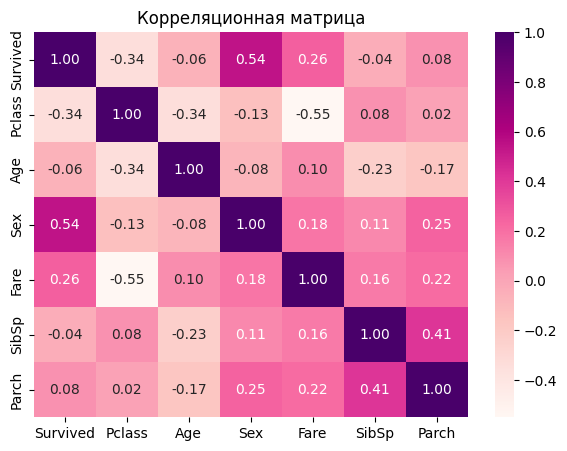

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

corr = df[["Survived", "Pclass", "Age", "Sex", "Fare", "SibSp", "Parch"]].copy()
corr["Sex"] = corr["Sex"].map({"male": 0, "female": 1})
corr["Age"] = corr["Age"].fillna(corr["Age"].median())

print(corr.corr()["Survived"].sort_values(ascending=False))

plt.figure(figsize=(7, 5))
sns.heatmap(
    corr.corr(),
    annot=True,
    fmt=".2f",
    cmap="RdPu"
)
plt.title("Корреляционная матрица")
plt.show()

Берём только числовые/закодированные признаки.

Sex и Age приводим к числам так же, как в модели.

.corr()["Survived"] — корреляция каждого признака с целевой переменной.

sort_values — сортировка: сразу видно самый сильный положительный и отрицательный признак.

heatmap — наглядная матрица корреляций.cmap="RdPu" — розовая палитра (Red → Purple): отрицательные значения светлее, положительные — насыщенно-розовые/пурпурные.

annot=True — подписывает значения в каждой ячейке.

fmt=".2f" — два знака после запятой.

Если нужен полностью розовый градиент без красного — замените cmap="RdPu" на cmap="PuRd" (Purple → Red) или cmap="pink".

